<a href="https://colab.research.google.com/github/sim07hamdani/FDM5-3P-Travaux/blob/main/00_environnement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aelkharrim/FDM5-3P/blob/main/notebooks/00_Environnement.ipynb)

# Séance 2 : installer et configurer Python (Windows, Linux) et utiliser Google Colab

Ce notebook accompagne la présentation de la séance 2 (FD, M5, Python pour la Physique). Vous pouvez le refaire chez vous, étape par étape.

**Comment l'utiliser**

* Les blocs `powershell` (Windows) et `bash` (Linux) sont des commandes à taper **dans un terminal**, pas dans une cellule de code.
* Les cellules de code Python se lancent avec `Maj + Entrée`. Elles fonctionnent sur Colab, sous Windows et sous Linux.
* Chaque étape se termine par une **vérification** : si elle échoue, consultez la section *Dépannage* à la fin.

**Plan**

1. Le terminal
2. Installer Python
3. pip, le gestionnaire de paquets
4. L'environnement virtuel (`venv`)
5. Jupyter en local
6. Google Colab
7. Aide-mémoire des commandes
8. Exemple complet : l'équation de la chaleur 2D
9. Dépannage et checklist

## 0. Où suis-je ?

Cette cellule affiche le système et la version de Python qui exécutent ce notebook. Sur Colab, c'est Linux ; chez vous, ce sera votre machine.

In [1]:
import platform
import sys

print("Système  :", platform.system(), platform.release())
print("Python   :", sys.version.split()[0])
print("Exécutable :", sys.executable)
print("Sur Colab ? :", "google.colab" in sys.modules)

Système  : Linux 6.6.159+
Python   : 3.13.18
Exécutable : /usr/bin/python3
Sur Colab ? : True


## 1. Le terminal

Le **terminal** est une fenêtre où l'on tape des commandes. Toute l'installation se fait par là.

| | Windows | Linux |
|---|---|---|
| Programme | **PowerShell** (ou Windows Terminal) | **Bash** (Terminal) |
| Ouvrir | touche Windows, taper `PowerShell`, Entrée | `Ctrl + Alt + T` |
| Invite | `PS C:\Users\vous>` | `vous@machine:~$` |

### Commandes de base (équivalents)

| Action | PowerShell (Windows) | Bash (Linux) |
|---|---|---|
| Où suis-je ? | `pwd` | `pwd` |
| Lister les fichiers | `ls` (ou `dir`) | `ls -la` |
| Changer de dossier | `cd dossier` | `cd dossier` |
| Dossier parent | `cd ..` | `cd ..` |
| Créer un dossier | `mkdir mon_projet` | `mkdir -p mon_projet` |
| Afficher un fichier | `cat fichier.txt` | `cat fichier.txt` |
| Copier | `cp a.txt b.txt` | `cp a.txt b.txt` |
| Déplacer / renommer | `mv a.txt b.txt` | `mv a.txt b.txt` |
| Supprimer un fichier | `rm a.txt` | `rm a.txt` |
| Où est ce programme ? | `Get-Command python` | `which python3` |
| Afficher le PATH | `$env:PATH` | `echo $PATH` |
| Effacer l'écran | `cls` | `clear` |
| Annuler la commande | `Ctrl + C` | `Ctrl + C` |

**Astuces** : `Tab` complète les noms ; la flèche haut rappelle la commande précédente.

Vérification (cette cellule fait la même chose que `pwd` et `ls`, sous tous les systèmes) :

In [2]:
from pathlib import Path

print("Dossier courant :", Path.cwd())
print("Contenu :", sorted(p.name for p in Path.cwd().iterdir())[:10])

Dossier courant : /content
Contenu : ['.config', 'sample_data']


## 2. Installer Python

### Windows

1. Allez sur [python.org/downloads](https://www.python.org/downloads/) et cliquez sur **Download Python**.
2. Lancez le fichier téléchargé. Dans la première fenêtre, **cochez « Add python.exe to PATH »**, puis cliquez sur *Install Now*.
3. **Fermez puis rouvrez PowerShell** (important), puis vérifiez :

```powershell
python --version
py --version        # le lanceur "py" gère plusieurs versions
Get-Command python  # où est python ?
```

> Si `python` ouvre le Microsoft Store : *Paramètres > Applications > Paramètres avancés > Alias d'exécution d'application*, puis désactivez les alias `python.exe` et `python3.exe`.

### Linux (Ubuntu / Debian)

```bash
sudo apt update
sudo apt install python3 python3-pip python3-venv
python3 --version
which python3
```

Sous Linux, la commande est `python3` (et `pip3`), pas `python`.

### Vérification dans Python

In [3]:
import sys
print(sys.version)
assert sys.version_info >= (3, 9), "Python trop ancien : installez une version récente"
print("OK : Python", sys.version_info.major, sys.version_info.minor)

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
OK : Python 3 13


## 3. pip, le gestionnaire de paquets

`pip` installe les bibliothèques Python depuis le dépôt [PyPI](https://pypi.org). **Bonne pratique** : écrire `python -m pip` (Windows : `py -m pip`) plutôt que `pip`, pour être sûr d'utiliser le pip de *cette* version de Python.

### Commandes essentielles

| Action | Commande |
|---|---|
| Mettre pip à jour | `python -m pip install --upgrade pip` |
| Installer un paquet | `python -m pip install numpy` |
| Installer plusieurs paquets | `python -m pip install numpy scipy matplotlib sympy` |
| Désinstaller | `python -m pip uninstall numpy` |
| Lister les paquets installés | `python -m pip list` |
| Détails d'un paquet | `python -m pip show numpy` |
| Exporter l'environnement | `python -m pip freeze > requirements.txt` |
| Réinstaller depuis le fichier | `python -m pip install -r requirements.txt` |

Sous Linux, remplacez `python` par `python3`. Sous Windows, remplacez-le par `py`.

### Dans un notebook : `%pip`

Dans une cellule, on utilise la commande magique `%pip` (pas `!pip`), qui installe dans l'environnement du notebook :

In [4]:
%pip install --quiet numpy scipy matplotlib sympy

In [5]:
%pip show numpy

Name: numpy
Version: 2.4.6
Summary: Fundamental package for array computing in Python
Home-page: https://numpy.org
Author: Travis E. Oliphant et al.
Author-email: 
License-Expression: BSD-3-Clause AND 0BSD AND MIT AND Zlib AND CC0-1.0
Location: /usr/local/lib/python3.13/dist-packages
Requires: 
Required-by: accelerate, access, albucore, albumentations, ale-py, arviz, astropy, autograd, bigframes, blis, blosc2, bokeh, Bottleneck, bqplot, clarabel, cmdstanpy, contourpy, cufflinks, cvxpy, cyipopt, datasets, db-dtypes, diffusers, dm-tree, dopamine_rl, esda, flax, folium, formulaic, geemap, geopandas, gradio, grain, gym, gymnasium, h5netcdf, h5py, hdbscan, highspy, holoviews, hyperopt, ImageIO, imbalanced-learn, inequality, jax, jaxlib, keras, keras-hub, libpysal, librosa, lightgbm, mapclassify, matplotlib, matplotlib-venn, mgwr, missingno, mizani, ml_dtypes, mlxtend, moviepy, music21, nibabel, numba, numexpr, opencv-contrib-python, opencv-python, opencv-python-headless, optax, orbax-checkp

Les versions des quatre bibliothèques de base (méthode de la bibliothèque standard) :

In [6]:
from importlib.metadata import version

for paquet in ["numpy", "scipy", "matplotlib", "sympy"]:
    print(f"{paquet:12s} {version(paquet)}")

numpy        2.4.6
scipy        1.16.3
matplotlib   3.10.0
sympy        1.14.0


## 4. Les environnements virtuels (`venv`)

**Pourquoi ?** Chaque projet peut avoir besoin de versions différentes des bibliothèques. Un *environnement virtuel* est un dossier qui contient une copie isolée de Python et de ses paquets : on n'installe jamais « à la main » dans le Python du système.

```
mon_projet/
└── .venv/            <- l'environnement (à ne pas partager)
    ├── pyvenv.cfg
    └── Scripts/ (Windows)  ou  bin/ (Linux)
```

### Windows (PowerShell)

```powershell
mkdir mon_projet
cd mon_projet
py -m venv .venv                  # 1. créer
.\.venv\Scripts\Activate.ps1      # 2. activer : l'invite affiche (.venv)
pip install numpy scipy matplotlib sympy   # 3. installer les bibliothèques
pip install jupyterlab                     # 4. installer Jupyter
pip list                                   # 5. vérifier
deactivate                                 # pour quitter l'environnement
```

> Si l'activation échoue avec « l'exécution de scripts est désactivée sur ce système », autorisez les scripts locaux (une seule fois) :
> ```powershell
> Set-ExecutionPolicy -Scope CurrentUser -ExecutionPolicy RemoteSigned
> ```

### Linux (Bash)

```bash
mkdir mon_projet && cd mon_projet
python3 -m venv .venv             # 1. créer
source .venv/bin/activate         # 2. activer : l'invite affiche (.venv)
pip install numpy scipy matplotlib sympy   # 3. installer les bibliothèques
pip install jupyterlab                     # 4. installer Jupyter
pip list                                   # 5. vérifier
deactivate                                 # pour quitter l'environnement
```

> Sous Debian 12 / Ubuntu 24.04 et plus récents, `pip install` hors d'un environnement virtuel échoue avec `externally-managed-environment` : c'est voulu, utilisez un `venv`.

### Reproduire un environnement

```bash
python -m pip freeze > requirements.txt     # sauvegarder
python -m pip install -r requirements.txt   # recréer ailleurs
```

### Démonstration (cellule portable)

Cette cellule crée un environnement minimal (sans pip, pour aller vite) dans un dossier temporaire et montre sa structure :

In [7]:
import subprocess
import sys
import tempfile
from pathlib import Path

dossier = Path(tempfile.mkdtemp()) / "demo-env"
subprocess.run([sys.executable, "-m", "venv", "--without-pip", str(dossier)], check=True)

for chemin in sorted(dossier.iterdir()):
    print(chemin.name)
print()
print((dossier / "pyvenv.cfg").read_text())

.gitignore
bin
include
lib
lib64
pyvenv.cfg

home = /usr/bin
include-system-site-packages = false
version = 3.13.18
executable = /usr/bin/python3.13
command = /usr/bin/python3 -m venv --without-pip /tmp/tmpjd6ysk6y/demo-env



## 5. Jupyter en local

**JupyterLab** ouvre les notebooks (`.ipynb`) dans votre navigateur. Il est déjà installé dans votre environnement virtuel (étape 4).

### Lancement

```powershell
# Windows
cd mon_projet
.\.venv\Scripts\Activate.ps1
jupyter lab
```

```bash
# Linux
cd mon_projet
source .venv/bin/activate
jupyter lab
```

Le navigateur s'ouvre sur `http://localhost:8888`. Pour arrêter le serveur : `Ctrl + C` dans le terminal. Comme JupyterLab est lancé depuis le venv activé, vos notebooks utilisent automatiquement les bibliothèques installées dans ce venv.

### Premier test

Dans JupyterLab : *Fichier > Nouveau > Notebook*, puis dans une cellule :

```python
import numpy as np
np.__version__
```

### Raccourcis utiles (mode commande : `Échap`)

| Touche | Action |
|---|---|
| `Maj + Entrée` | exécuter la cellule, passer à la suivante |
| `Ctrl + Entrée` | exécuter la cellule |
| `A` / `B` | insérer une cellule au-dessus / en dessous |
| `M` / `Y` | cellule texte (Markdown) / cellule code |
| `D D` | supprimer la cellule |

Vérification : quel Python exécute ce notebook ?

In [8]:
import sys
print("Python du notebook :", sys.executable)

Python du notebook : /usr/bin/python3


## 6. Google Colab (exécution dans le cloud)

**Colab** exécute les notebooks sur des serveurs Google : aucune installation, et NumPy, SciPy, Matplotlib et SymPy sont déjà présents. Il suffit d'un compte Google. La machine est sous **Linux**.

### Ouvrir un notebook depuis GitHub

1. Allez sur [colab.research.google.com](https://colab.research.google.com).
2. *Fichier > Ouvrir le notebook*, onglet **GitHub**, collez l'URL du dépôt, choisissez le notebook.
   *Ou plus simple* : cliquez sur le bouton **Open in Colab** en haut du notebook.
3. *Exécution > Modifier le type d'exécution* : Python 3 (le GPU n'est pas nécessaire ici).
4. Exécutez les cellules avec `Maj + Entrée`.

### Ce qu'il faut savoir

| Sujet | Sur Colab |
|---|---|
| Commandes shell | préfixe `!` : `!ls`, `!python script.py` |
| Installer un paquet | `%pip install nom` (à refaire à chaque nouvelle session) |
| Fichiers | panneau *Fichiers* (icône de dossier à gauche) : glisser-déposer pour envoyer |
| Télécharger un fichier | `from google.colab import files` puis `files.download("fichier.png")` |
| Google Drive | `from google.colab import drive` puis `drive.mount("/content/drive")` |
| Sauvegarder vos modifications | *Fichier > Enregistrer une copie dans Drive* |
| Session | **temporaire** : à la fin, les fichiers créés et les paquets installés disparaissent |

Pour télécharger un fichier depuis Colab, dans une cellule :

In [9]:
# Fonctionne uniquement sur Colab
if "google.colab" in __import__("sys").modules:
    from google.colab import files
    # files.download("chaleur2d.png")   # à décommenter après l'étape 8
    print("Colab : téléchargement et montage de Drive disponibles")
else:
    print("Vous êtes en local : ce bloc ne sert pas ici")

Colab : téléchargement et montage de Drive disponibles


### Local ou Colab ?

| | Local (venv) | Colab |
|---|---|---|
| Installation | oui, une fois | aucune |
| Fonctionne hors ligne | oui | non |
| Fichiers conservés | oui | non (sauf Drive) |
| Puissance | celle de votre PC | serveur Google (GPU possible) |
| Reproductibilité | contrôlée (`requirements.txt`) | dépend de l'image Colab |
| Idéal pour | projets durables | cours, essais rapides, partage |

## 7. Aide-mémoire des commandes

### Python et environnements

| Action | Windows (PowerShell) | Linux (Bash) |
|---|---|---|
| Version de Python | `python --version` ou `py --version` | `python3 --version` |
| Lancer un script | `python script.py` | `python3 script.py` |
| Lancer Python interactif | `python` (quitter : `exit()`) | `python3` |
| Créer un venv | `py -m venv .venv` | `python3 -m venv .venv` |
| Activer le venv | `.\.venv\Scripts\Activate.ps1` | `source .venv/bin/activate` |
| Quitter le venv | `deactivate` | `deactivate` |
| Installer un paquet | `python -m pip install nom` | `python -m pip install nom` |
| Sauver / recréer | `pip freeze > requirements.txt` / `pip install -r requirements.txt` | idem |
| Installer Python | installateur de python.org | `sudo apt install python3 python3-pip python3-venv` |
| Installer Jupyter | `pip install jupyterlab` | `pip install jupyterlab` |
| Lancer JupyterLab | `jupyter lab` | `jupyter lab` |

### Dans un notebook

| Besoin | Commande |
|---|---|
| Installer un paquet | `%pip install nom` |
| Commande shell (Colab, Linux) | `!ls` |
| Changer de dossier | `%cd dossier` |
| Écrire un fichier | `%%writefile nom.py` (première ligne de la cellule) |
| Exécuter un script | `%run nom.py` |
| Chronométrer | `%%timeit` |

## 8. Exemple complet : l'équation de la chaleur 2D

Pour tester l'installation, on résout l'équation de la chaleur sur le carré $[0,1]^2$ :

$$\frac{\partial u}{\partial t} = \alpha \left(\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2}\right), \qquad u = 0 \text{ sur le bord}, \qquad u(x,y,0) = \sin(\pi x)\sin(\pi y)$$

La solution exacte est $u(x,y,t) = \sin(\pi x)\sin(\pi y)\, e^{-2\pi^2 \alpha t}$, ce qui permet de **vérifier** la solution numérique.

Chaque bibliothèque a son rôle :

| Bibliothèque | Rôle dans le script |
|---|---|
| **SymPy** | vérifie symboliquement que la solution exacte satisfait l'équation, puis la transforme en fonction numérique (`lambdify`) |
| **NumPy** | grille $(x, y)$ et tableaux de températures |
| **SciPy** | matrice creuse du laplacien, schéma de Crank-Nicolson, factorisation LU |
| **Matplotlib** | cartes de température et courbe d'erreur |

La cellule suivante écrit le script `chaleur2d.py` sur le disque (c'est le même fichier que celui de la séance) :

In [10]:
%%writefile chaleur2d.py
"""Équation de la chaleur 2D : du/dt = alpha * (d2u/dx2 + d2u/dy2) sur [0,1]x[0,1].

Condition initiale : u(x, y, 0) = sin(pi x) sin(pi y), u = 0 sur le bord.
Les quatre bibliothèques de base sont utilisées :
  - sympy      : solution analytique et vérification symbolique de l'EDP
  - numpy      : grille et tableaux
  - scipy      : matrice creuse du laplacien et schéma de Crank-Nicolson
  - matplotlib : figures

Usage :  python chaleur2d.py
"""
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sps
import sympy as sp
from scipy.sparse.linalg import splu

ALPHA = 0.1      # diffusivité thermique
N = 50           # points intérieurs par direction
DT = 0.005       # pas de temps
T_FIN = 0.5      # durée simulée


def solution_analytique():
    """Renvoie u(x, y, t) sous forme de fonction numpy, après vérification symbolique."""
    x, y, t, a = sp.symbols("x y t alpha", positive=True)
    u = sp.sin(sp.pi * x) * sp.sin(sp.pi * y) * sp.exp(-2 * sp.pi**2 * a * t)
    residu = sp.diff(u, t) - a * (sp.diff(u, x, 2) + sp.diff(u, y, 2))
    print("Résidu de l'EDP pour la solution exacte :", sp.simplify(residu))
    return sp.lambdify((x, y, t), u.subs(a, ALPHA), "numpy")


def resoudre(n=N, dt=DT, t_fin=T_FIN):
    """Schéma de Crank-Nicolson sur une grille n x n. Renvoie grille, états et erreurs."""
    h = 1.0 / (n + 1)
    x = np.linspace(h, 1 - h, n)
    X, Y = np.meshgrid(x, x, indexing="ij")

    # laplacien 2D creuse : L = I (x) T + T (x) I
    T = sps.diags([1.0, -2.0, 1.0], [-1, 0, 1], shape=(n, n)) / h**2
    I = sps.identity(n)
    L = sps.kron(I, T) + sps.kron(T, I)

    A = sps.identity(n * n) - 0.5 * dt * ALPHA * L
    B = sps.identity(n * n) + 0.5 * dt * ALPHA * L
    lu = splu(A.tocsc())                      # factorisation faite une seule fois

    u_exact = solution_analytique()
    u = u_exact(X, Y, 0.0).ravel()
    n_pas = round(t_fin / dt)
    etats, erreurs = {0: u.reshape(n, n).copy()}, []
    for k in range(1, n_pas + 1):
        u = lu.solve(B @ u)
        erreurs.append(np.abs(u - u_exact(X, Y, k * dt).ravel()).max())
        if k in (n_pas // 2, n_pas):
            etats[k] = u.reshape(n, n).copy()
    return X, Y, etats, np.array(erreurs), dt


def tracer(X, Y, etats, erreurs, dt, fichier="chaleur2d.png"):
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
    vmax = etats[0].max()
    for ax, (k, u) in zip(axes[:3], etats.items()):
        im = ax.pcolormesh(X, Y, u, cmap="inferno", vmin=0, vmax=vmax, shading="auto")
        ax.set_title(f"t = {k * dt:.2f}")
        ax.set_aspect("equal")
    fig.colorbar(im, ax=axes[:3], shrink=0.8, label="température")
    axes[3].semilogy(dt * np.arange(1, len(erreurs) + 1), erreurs)
    axes[3].set_xlabel("t")
    axes[3].set_ylabel("erreur max")
    axes[3].set_title("numérique vs analytique")
    fig.savefig(fichier, dpi=120, bbox_inches="tight")
    print("Figure enregistrée :", fichier)
    return fig


if __name__ == "__main__":
    X, Y, etats, erreurs, dt = resoudre()
    print(f"Erreur maximale sur [0, {T_FIN}] : {erreurs.max():.2e}")
    tracer(X, Y, etats, erreurs, dt)
    if matplotlib.get_backend().lower() != "agg":
        plt.show()

Writing chaleur2d.py


### Exécution

**Dans ce notebook** (Colab, Windows ou Linux) :

Résidu de l'EDP pour la solution exacte : 0
Erreur maximale sur [0, 0.5] : 1.13e-04
Figure enregistrée : chaleur2d.png


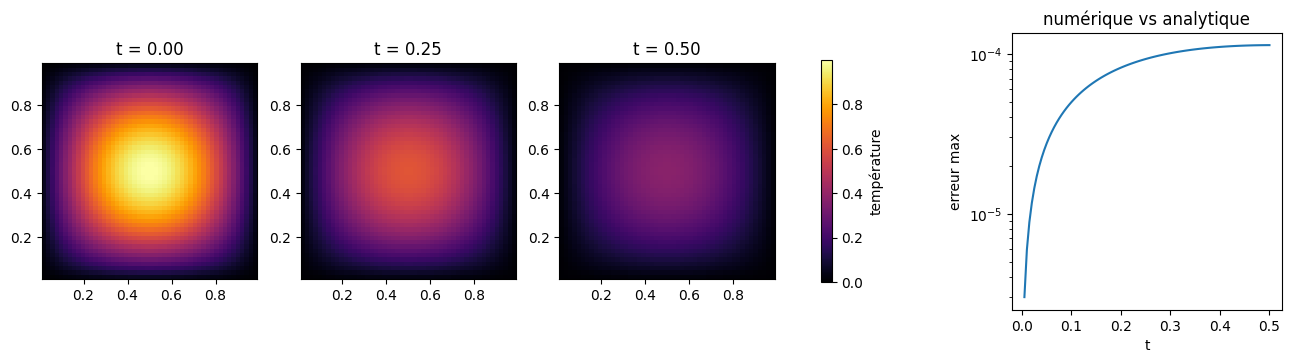

<Figure size 640x480 with 0 Axes>

In [11]:
%run chaleur2d.py

**Dans un terminal, en local** (environnement activé, les 4 bibliothèques installées) :

```powershell
# Windows
python chaleur2d.py
```

```bash
# Linux
python3 chaleur2d.py
```

**Sur Colab, en ligne de commande** : `!python chaleur2d.py`, puis affichage de l'image enregistrée :

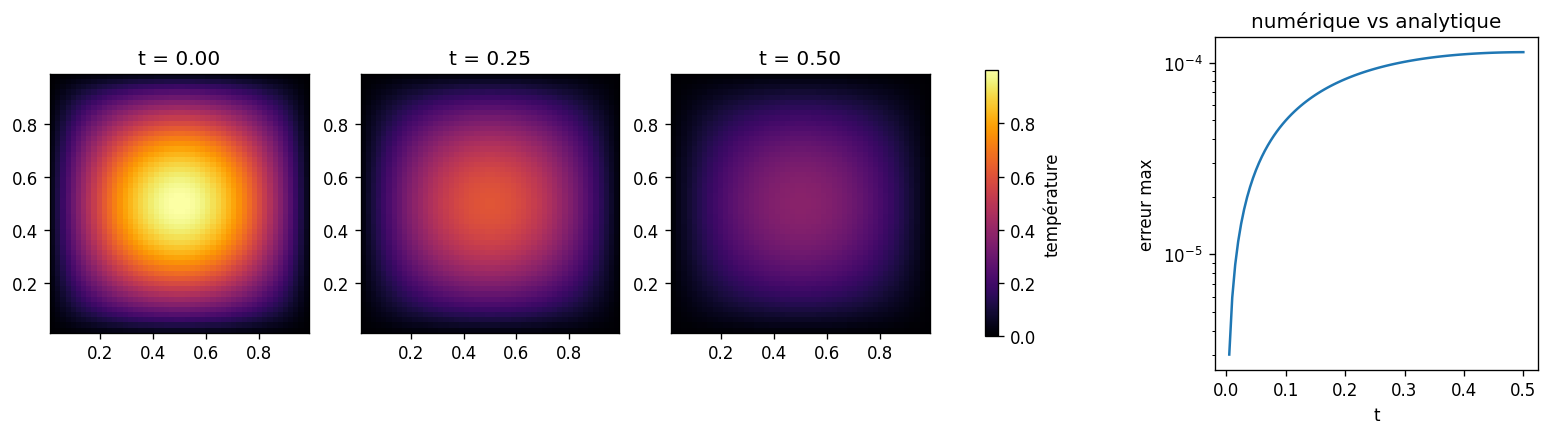

In [12]:
from IPython.display import Image

Image("chaleur2d.png")

### Résultat attendu

* La ligne `Résidu de l'EDP pour la solution exacte : 0` (vérification symbolique).
* Une erreur maximale de l'ordre de `1e-04` entre numérique et analytique.
* Une figure `chaleur2d.png` : la température diffuse et décroît, l'erreur reste petite.

**À essayer** : changez `ALPHA`, `N` ou `DT` dans le script et relancez-le. Que se passe-t-il quand `N` double ?

## 9. Dépannage

| Symptôme | Cause probable | Solution |
|---|---|---|
| `python` : commande introuvable (Windows) | Python absent du PATH | Réinstaller en cochant *Add to PATH*, ou utiliser `py` ; rouvrir PowerShell |
| `python` ouvre le Microsoft Store | Alias d'exécution actif | Désactiver les alias `python.exe` / `python3.exe` |
| `Activate.ps1` : exécution de scripts désactivée | Politique PowerShell | `Set-ExecutionPolicy -Scope CurrentUser -ExecutionPolicy RemoteSigned` |
| `python` : commande introuvable (Linux) | La commande est `python3` | Utiliser `python3` |
| `externally-managed-environment` | Pip hors venv sur un Linux récent | Créer et activer un `venv` |
| `ensurepip is not available` | Paquet venv absent (Debian/Ubuntu) | `sudo apt install python3-venv` |
| `ModuleNotFoundError: No module named 'numpy'` | Paquet absent de *cet* environnement | Activer le bon environnement, puis `python -m pip install numpy` |
| `jupyter` : commande introuvable | Venv non activé, ou Jupyter non installé | Activer le venv, puis `pip install jupyterlab` |
| Colab : paquet disparu après un moment | Session temporaire | Relancer `%pip install`, enregistrer sur Drive |

## Checklist à faire chez vous

- [ ] Ouvrir un terminal (PowerShell ou Bash)
- [ ] Installer Python et vérifier `python --version`
- [ ] Créer et activer un environnement virtuel
- [ ] Installer `numpy scipy matplotlib sympy jupyterlab` avec pip
- [ ] Lancer `jupyter lab` et ouvrir un notebook
- [ ] Exécuter `chaleur2d.py` en local
- [ ] Ouvrir ce notebook sur Colab et exécuter `chaleur2d.py` dans le cloud